<a href="https://colab.research.google.com/github/ingnur5/AlgoritmosOptimizacion/blob/main/Proyecto_Redes_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Carga del conjunto de datos

### Carga de dataset

In [ ]:
# Conectamos con nuestro Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Establezco una ruta absoluta a un directorio existente de mi Google Drive
BASE_FOLDER = "/content/drive/MyDrive/Proyecto_Redes_Neuronales/"

In [ ]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_FOLDER = Path("/content/drive/MyDrive/Proyecto_Redes_Neuronales")
else:
    # En local: carpeta donde se encuentra este notebook
    BASE_FOLDER = Path.cwd()

DATASET_DIR = BASE_FOLDER / "Dataset"

# Carpetas de salida: modelos entrenados e historiales de entrenamiento
MODELS_DIR = BASE_FOLDER / "models"
HISTORY_DIR = BASE_FOLDER / "histories"
for d in (MODELS_DIR, HISTORY_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Entorno      : {'Google Colab' if IN_COLAB else 'Local'}")
print(f"BASE_FOLDER  : {BASE_FOLDER}")
print(f"DATASET_DIR  : {DATASET_DIR}  (Dataset Listo: {DATASET_DIR.exists()})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno      : Google Colab
BASE_FOLDER  : /content/drive/MyDrive/Proyecto_Redes_Neuronales
DATASET_DIR  : /content/drive/MyDrive/Proyecto_Redes_Neuronales/Dataset  (Dataset Listo: True)


In [ ]:
import gc
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)  # fija semillas de Python, NumPy y TensorFlow

# Parámetros globales
IMG_SIZE_SCRATCH = 64     # tamaño nativo del dataset
IMG_SIZE_TL = 160         # tamaño para redes preentrenadas (Xception/InceptionV3 exigen >= 71/75 px)
BATCH_SIZE = 32
EPOCHS_SCRATCH = 80
EPOCHS_FEATURE_EXTRACTION = 30
EPOCHS_FINE_TUNING = 30
FORCE_RETRAIN = False

CLASS_NAMES = ["non_smile", "smile"]  # índice = etiqueta

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: []


In [ ]:
VALID_EXT = (".jpg", ".jpeg", ".png")

def build_inventory(dataset_dir):
    """Construye el inventario de imágenes etiquetadas.

    Args:
        dataset_dir (Path): carpeta que contiene las subcarpetas `smile/` y `non_smile/`.

    Returns:
        pd.DataFrame: una fila por imagen con las columnas `path`, `filename`,
            `label` (0/1), `class_name` y `person`.
    """
    records = []
    for label, class_name in enumerate(CLASS_NAMES):
        for img_path in sorted((dataset_dir / class_name).iterdir()):
            if img_path.suffix.lower() in VALID_EXT:
                records.append({
                    "path": str(img_path),
                    "filename": img_path.name,
                    "label": label,
                    "class_name": class_name,
                    "person": img_path.stem.rsplit("_", 1)[0],
                })
    return pd.DataFrame(records)

df = build_inventory(DATASET_DIR)

# La carpeta test/ NO tiene etiquetas: se usa solo para predicciones cualitativas al final
unlabeled_paths = sorted(str(p) for p in (DATASET_DIR / "test").iterdir()
                         if p.suffix.lower() in VALID_EXT)

print(f"Imágenes etiquetadas : {len(df)}")
print(f"Imágenes sin etiqueta: {len(unlabeled_paths)} (carpeta test/)")
df.head()

Imágenes etiquetadas : 1116
Imágenes sin etiqueta: 7160 (carpeta test/)


,path,filename,label,class_name,person
0,/content/drive/MyDrive/Proyecto_Redes_Neuronal...,Aaron_Eckhart_0001.jpg,0,non_smile,Aaron_Eckhart
1,/content/drive/MyDrive/Proyecto_Redes_Neuronal...,Aaron_Patterson_0001.jpg,0,non_smile,Aaron_Patterson
2,/content/drive/MyDrive/Proyecto_Redes_Neuronal...,Abdel_Nasser_Assidi_0002.jpg,0,non_smile,Abdel_Nasser_Assidi
3,/content/drive/MyDrive/Proyecto_Redes_Neuronal...,Abdoulaye_Wade_0004.jpg,0,non_smile,Abdoulaye_Wade
4,/content/drive/MyDrive/Proyecto_Redes_Neuronal...,Abdulaziz_Kamilov_0001.jpg,0,non_smile,Abdulaziz_Kamilov


## 2. Inspección del conjunto de datos

### 2.1 Distribución de clases

Si las clases están balanceadas, la *accuracy* es una métrica representativa y el rendimiento estocástico de referencia es ≈ 50 %.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os

def show_image_from_folder(folder):
  # Escogiendo y mostrando una imagen al azar del conjunto de test
  folder_path = BASE_FOLDER + f'Dataset/{folder}/'

  # Listamos todos los archivos en la carpeta
  files_in_folder = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

  # Seleccionamos un archivo aleatorio de la lista real
  random_filename = np.random.choice(files_in_folder)
  img_path = os.path.join(folder_path, random_filename)

  # Leemos la imagen
  img = cv2.imread(img_path)

  # Convertimos el espacio de color de BGR a RGB y la visualizamos
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  plt.imshow(img)
  plt.title(random_filename)
  plt.axis('off')
  plt.show()

### Exploración dataset smile:

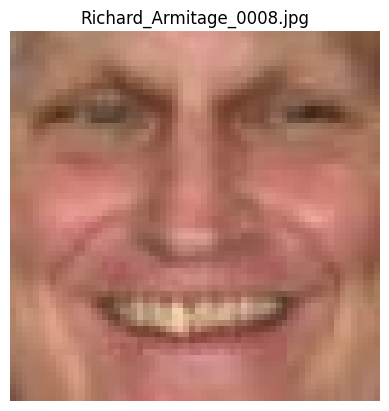

In [ ]:
show_image_from_folder("smile")

### Exploración dataset non_smile:

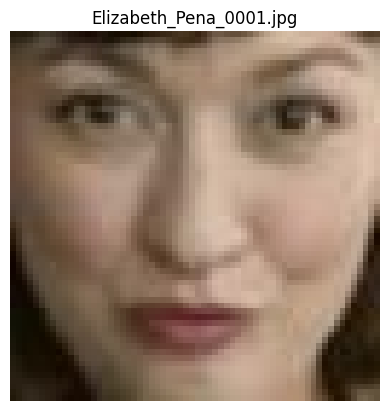

In [ ]:
show_image_from_folder("non_smile")

### 2.1 Distribución de clases

Si las clases están balanceadas, la *accuracy* es una métrica representativa y el rendimiento estocástico de referencia es ≈ 50 %.

In [ ]:
class_counts = df["class_name"].value_counts().reindex(CLASS_NAMES)
print(class_counts)

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(class_counts.index, class_counts.values, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars)
ax.set_title("Distribución de clases (imágenes etiquetadas)")
ax.set_ylabel("Nº de imágenes")
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

## 3. Acondicionamiento del conjunto

## 4. Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución

#### Estrategia 2: Red pre-entrenada

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import (ResNet50, DenseNet121, MobileNetV2)

In [ ]:
arquitecturas = {
    "ResNet50": ResNet50(weights='imagenet', include_top=True),
    "MobileNetV2": MobileNetV2(weights='imagenet', include_top=True),
    "DenseNet121": DenseNet121(weights='imagenet', include_top=True)
}


102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
33188688/33188688 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Modelo               | Tamaño de Entrada    | Total Parámetros  
----------------------------------------------------------------


In [ ]:
modelo_resnet50 = ResNet50(weights='imagenet', include_top=True)
modelo_resnet50.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [ ]:
from deepface import DeepFace

# Analiza la imagen directamente
analysis = DeepFace.analyze(img_path="persona.jpg", actions=['emotion'])
print(analysis[0]['dominant_emotion']) # Imprime si está feliz/sonriendo

## 5. Monitorización del proceso de entrenamiento para la toma de decisiones

## 6. Evaluación del modelo predictivo y planteamiento de la siguiente prueba experimental